# Notebook 4: Pretrained Diffusion Model (Stable Diffusion), no API key version
**Assignment-02 | Activity B (CO4): Image Generation** | Prepared by: Manmath (Research & Code Lead)

| | |
|---|---|
| **What to run** | Run all cells top to bottom. No account, token or API key is needed. |
| **Where output appears** | Cell 6 shows one image per prompt (saved as `B2_SD_prompt1.png`, `B2_SD_prompt2.png`, `B2_SD_prompt3.png`). |
| **Expected runtime** | First run: about 3-6 min (model download of roughly 4-5 GB). After that about 5-10 s per image on a T4. |
| **Runtime setting** | Runtime -> Change runtime type -> **T4 GPU**, then **Runtime -> Run all** |

> The pretrained model runs **inside Colab** using the open-source Hugging Face `diffusers` library. The weights are public, so the free Colab GPU is all you need. Nothing is trained.

## 1. Idea in brief
Stable Diffusion is a **latent diffusion model** with three parts:
1. **Text encoder (CLIP)** turns the prompt into embeddings.
2. **U-Net** repeatedly removes noise from a *latent* image, guided by the text embeddings (cross-attention).
3. **VAE decoder** converts the final clean latent into a full-size image.

Generation starts from random noise in latent space and denoises it over many steps (here 30).

               ## 2. Install libraries and check the GPU

In [1]:
!pip -q install diffusers transformers accelerate safetensors

import time, torch
import matplotlib.pyplot as plt
from diffusers import StableDiffusionPipeline, DPMSolverMultistepScheduler

assert torch.cuda.is_available(), "No GPU found: Runtime -> Change runtime type -> T4 GPU"
print("GPU:", torch.cuda.get_device_name(0))

GPU: Tesla T4


## 3. Load the pretrained pipeline (downloads once, no key needed)

In [2]:
# Public model repos, tried in order. The first one that downloads is used.
MODEL_CANDIDATES = [
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    "CompVis/stable-diffusion-v1-4",
]

pipe, MODEL_ID = None, None
for m in MODEL_CANDIDATES:
    try:
        pipe = StableDiffusionPipeline.from_pretrained(m, torch_dtype=torch.float16)
        MODEL_ID = m
        break
    except Exception as e:
        print(f"Could not load {m}: {type(e).__name__}")
assert pipe is not None, "No model could be loaded. Check the internet connection of the Colab session."

pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)  # good quality in ~20-30 steps
pipe = pipe.to("cuda")
pipe.enable_attention_slicing()   # saves GPU memory
print("Loaded:", MODEL_ID)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loaded: stable-diffusion-v1-5/stable-diffusion-v1-5


## 4. The three internal components (useful for Q&A)

In [3]:
def millions(module):
    return sum(p.numel() for p in module.parameters()) / 1e6

print(f"Text encoder (CLIP) : {millions(pipe.text_encoder):7.1f} M parameters")
print(f"U-Net (denoiser)    : {millions(pipe.unet):7.1f} M parameters")
print(f"VAE (enc + dec)     : {millions(pipe.vae):7.1f} M parameters")
print("Scheduler           :", type(pipe.scheduler).__name__)

Text encoder (CLIP) :   123.1 M parameters
U-Net (denoiser)    :   859.5 M parameters
VAE (enc + dec)     :    83.7 M parameters
Scheduler           : DPMSolverMultistepScheduler


## 5. Fixed prompts and settings (same prompts are recorded in the Prompts Log)

In [4]:
PROMPTS = [
    "A golden retriever sitting on a wooden bench in a park, soft morning light, photorealistic",
    "A futuristic city skyline at sunset with flying cars, cinematic, highly detailed",
    "A red sneaker on a white background, studio product photo",
]
NEGATIVE_PROMPT = "blurry, low quality, distorted, extra limbs, text, watermark"
SEED, STEPS, GUIDANCE = 42, 30, 7.5

images, times = [], []
for i, p in enumerate(PROMPTS, 1):
    gen = torch.Generator("cuda").manual_seed(SEED)   # fixed seed -> reproducible output
    t0 = time.time()
    img = pipe(p, negative_prompt=NEGATIVE_PROMPT, num_inference_steps=STEPS,
               guidance_scale=GUIDANCE, generator=gen).images[0]
    times.append(time.time() - t0)
    img.save(f"B2_SD_prompt{i}.png"); images.append(img)
    print(f"Prompt {i}: {times[-1]:.1f} s -> B2_SD_prompt{i}.png")

  0%|          | 0/30 [00:00<?, ?it/s]

Prompt 1: 9.3 s -> B2_SD_prompt1.png


  0%|          | 0/30 [00:00<?, ?it/s]

Prompt 2: 6.1 s -> B2_SD_prompt2.png


  0%|          | 0/30 [00:00<?, ?it/s]

Prompt 3: 6.1 s -> B2_SD_prompt3.png


## 6. Display results (screenshot this cell)

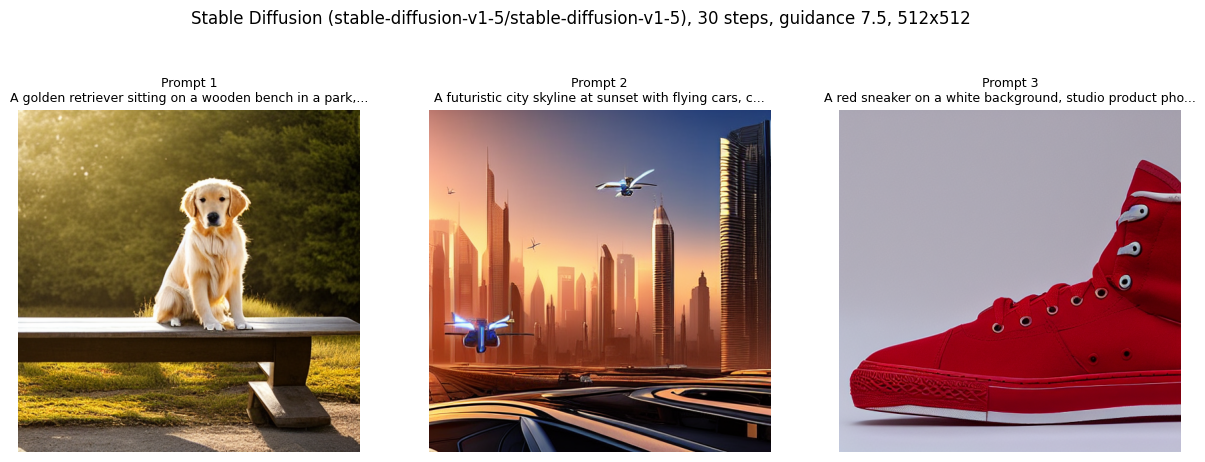

In [5]:
fig, axes = plt.subplots(1, len(images), figsize=(5 * len(images), 5.6))
for i, (ax, img, p) in enumerate(zip(axes, images, PROMPTS), 1):
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"Prompt {i}\n" + (p[:55] + "..." if len(p) > 55 else p), fontsize=9)
fig.suptitle(f"Stable Diffusion ({MODEL_ID}), {STEPS} steps, guidance {GUIDANCE}, 512x512")
plt.savefig("B2_SD_all.png", dpi=200, bbox_inches="tight"); plt.show()

## 7. Optional extra: effect of the number of denoising steps
Useful for the analysis: fewer steps are faster but less detailed.

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

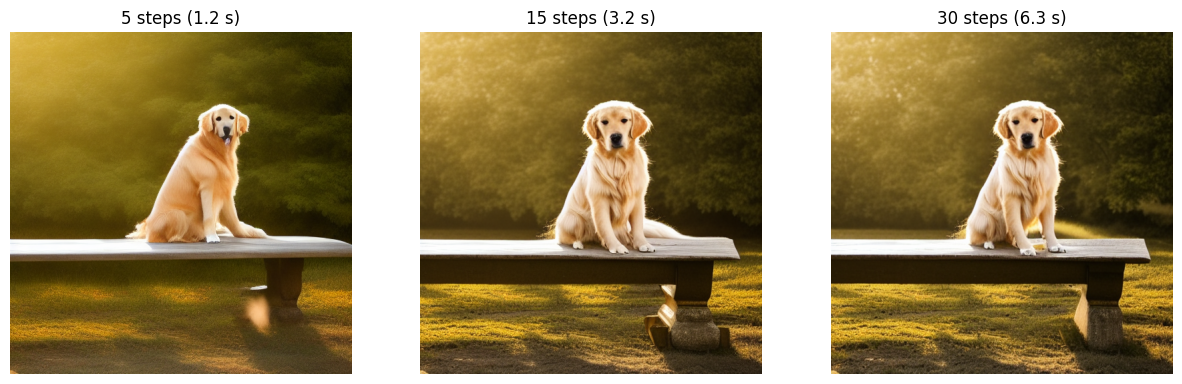

In [6]:
prompt = PROMPTS[0]
step_list = [5, 15, 30]
fig, axes = plt.subplots(1, len(step_list), figsize=(5 * len(step_list), 5.4))
for ax, s in zip(axes, step_list):
    gen = torch.Generator("cuda").manual_seed(SEED)
    t0 = time.time()
    im = pipe(prompt, num_inference_steps=s, guidance_scale=GUIDANCE, generator=gen).images[0]
    ax.imshow(im); ax.axis("off"); ax.set_title(f"{s} steps ({time.time() - t0:.1f} s)")
plt.savefig("B2b_SD_steps.png", dpi=200, bbox_inches="tight"); plt.show()

## 8. Observation notes (copy into the Observation Table)
- Realism / detail: ______  | Prompt following: ______  | Artifacts (anatomy, text, edges): ______
- Runtime per image: see printed times above.
- Compared with DCGAN: resolution (512x512 vs 28x28), variety, text control, compute cost.

### If Colab gives an out-of-memory error
Runtime -> Restart session, then run again. If it still fails, add `pipe.enable_vae_slicing()` after the `enable_attention_slicing()` line.
### If a model download fails
Re-run the loading cell once (temporary network error). The notebook automatically tries the second model in `MODEL_CANDIDATES`.